# 04 – Error analysis: where is the model wrong, and why?

**Research question.** What do the genes the model mispredicts have in common, and which explanations does the evidence support?

**Biological motivation.** An error is information. A false positive can point to an alternative the cell has and the model lacks, to a nutrient the cells had access to, or to a doubtful label. A false negative can point to an alternative the model allows but the cell cannot use, or to a function outside metabolism. Sorting the errors by evidence turns a score into testable hypotheses about *E. coli* metabolism.

**What this notebook does.**
- lists the genes where the FBA prediction and the Keio label disagree (the two matched comparisons of notebook 03)
- collects **evidence** for each of them from the model and from the experimental tables
- follows one false negative, *glyA*, in detail
- tests a few "what if" scenarios suggested by the literature

**Expected outputs.**
- `results/tables/errors_glucose.csv` and `errors_lb.csv`: one row per mispredicted gene with all evidence columns
- `results/tables/error_groups.csv`, `scenarios.csv`
- `results/figures/error_evidence_groups.png`

Two kinds of error:

- **False positive (FP)**: the model says *essential*, but a deletion mutant exists (and grows). Either the model lacks an alternative the cell has, or the simulated medium lacks something the cell had, or the label is wrong.
- **False negative (FN)**: the model says *dispensable*, but no viable mutant was found. Either the model uses a route the cell cannot use (not expressed, too slow, toxic intermediate), or the gene has an essential role outside metabolism, or the label is wrong.

The code below sorts the errors into *evidence groups*. A group states what the model and the data show; it is not a verdict on the cause. Deciding the most likely cause for each group is the part to think through yourself (section 6).

Rule for this notebook: the model is **not** changed to get a better score. Scenarios in section 5 are diagnostic and are reported next to the baseline, never instead of it.

Runtime: about 6 minutes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecoli_fba import RESULTS_DIR, annotation, errors, evaluate, keio, knockout, media, plotting
from ecoli_fba.model import load_model

plotting.apply_style()
pd.set_option("display.max_colwidth", 80)
TABLES_DIR = RESULTS_DIR / "tables"

model = load_model()
glucose_medium = media.glucose_minimal_medium(model)
lb_medium, _ = media.lb_like_medium(model, glucose_medium)

labels = keio.build_labels(keio.read_baba_table_s3(), keio.read_yamamoto_table_s5())
gene_annotation = annotation.annotate_genes(model).drop(columns="gene_name")

COMPARISONS = {
    "B: LB-like": {"file": "comparison_lb.csv", "medium": lb_medium, "label": "lb_essential", "out": "errors_lb.csv"},
    "C: glucose minimal": {"file": "comparison_glucose.csv", "medium": glucose_medium, "label": "glucose_essential", "out": "errors_glucose.csv"},
}
comparison = {name: pd.read_csv(TABLES_DIR / spec["file"]) for name, spec in COMPARISONS.items()}

## 1. How many errors, and are they the same genes on both media?

In [2]:
outcome_counts = pd.DataFrame({name: table["outcome"].value_counts() for name, table in comparison.items()}).loc[list(evaluate.OUTCOMES)]
outcome_counts

,B: LB-like,C: glucose minimal
outcome,,
TP,87,161
FP,29,34
FN,33,52
TN,1359,1261


In [3]:
def error_genes(name, outcome):
    table = comparison[name]
    return set(table.loc[table["outcome"] == outcome, "gene_name"])

overlap = {}
for outcome in ["FP", "FN"]:
    b, c = error_genes("B: LB-like", outcome), error_genes("C: glucose minimal", outcome)
    overlap[outcome] = {"only in B": len(b - c), "in both": len(b & c), "only in C": len(c - b)}
    print(f"{outcome} in both comparisons:", ", ".join(sorted(b & c)))
pd.DataFrame(overlap).T

FP in both comparisons: aroD, bioA, coaA, coaE, dapF, fabH, folB, folP, glmM, hemE, kdsC, lptB, luxS, mtn, pabA, pabB, yrbG, zupT
FN in both comparisons: acpS, adk, alsK, can, cydA, cydC, dut, eno, entD, fabA, fbaA, fldA, folA, folD, gapA, gpsA, hemH, ligA, lnt, nrdA, nrdB, pgk, pgsA, plsB, ppa, prs, pyrH, spoT, suhB, waaU, wzyE


,only in B,in both,only in C
FP,11,18,16
FN,2,31,21


## 2. Evidence for every mispredicted gene

**From the model**
- `subsystems`: pathways of the gene's reactions
- `lost_reactions` / `n_reactions_lost`: reactions that stop when only this gene is deleted
- `backup_genes`: other genes that can catalyse its remaining reactions (isozymes or alternative complexes)
- `growth_ratio`: knockout growth relative to wild type
- `blocked_precursors` (FP only): biomass ingredients the knockout can no longer make
- `rescuing_nutrients` (FP only): every nutrient that, added on its own to the medium, lets the knockout grow again

**From the experiments**
- `od_lb_22h`, `od_mops_24h`, `od_mops_48h`: growth of the Keio mutant (Baba et al. 2006)
- `pec`: essentiality call of the independent PEC database as listed in the Keio table (E essential, N non-essential, u unknown)
- `duplication_2009`: both isolates of the mutant still carry an intact copy of the gene (Yamamoto et al. 2009)

In [4]:
def metabolite_names(ids, strip_exchange=False):
    names = []
    for item in filter(None, ids.split("; ")):
        if strip_exchange:
            names.append(model.reactions.get_by_id(item).reactants[0].name)
        else:
            names.append(model.metabolites.get_by_id(item).name)
    return "; ".join(names)


def collect_evidence(name):
    spec = COMPARISONS[name]
    table = comparison[name]
    wrong = table[table["outcome"].isin(["FP", "FN"])]
    wrong = wrong.merge(gene_annotation, on="gene_id").merge(
        labels[["gene_id", "od_lb_22h", "od_mops_24h", "od_mops_48h", "pec", "duplication_2009"]], on="gene_id"
    )
    false_positives = wrong.loc[wrong["outcome"] == "FP", "gene_id"].tolist()
    with model:
        media.apply_medium(model, spec["medium"])
        blocked = errors.blocked_biomass_precursors(model, false_positives)
        rescue = errors.single_nutrient_rescue(model, false_positives)
    wrong = wrong.merge(blocked, on="gene_id", how="left").merge(rescue, on="gene_id", how="left")
    for column, strip in [("blocked_precursors", False), ("rescuing_nutrients", True)]:
        wrong[column] = wrong[column].fillna("").map(lambda ids: metabolite_names(ids, strip))

    is_fp = wrong["outcome"] == "FP"
    wrong["evidence_group"] = ""
    wrong.loc[is_fp, "evidence_group"] = errors.group_false_positives(wrong[is_fp])
    wrong.loc[~is_fp, "evidence_group"] = errors.group_false_negatives(wrong[~is_fp])
    wrong.sort_values(["outcome", "evidence_group", "gene_name"]).to_csv(TABLES_DIR / spec["out"], index=False)
    return wrong


evidence = {name: collect_evidence(name) for name in COMPARISONS}
{name: table["outcome"].value_counts().to_dict() for name, table in evidence.items()}

{'B: LB-like': {'FN': 33, 'FP': 29},
 'C: glucose minimal': {'FN': 52, 'FP': 34}}

## 3. False positives: predicted essential, but the mutant is viable

Evidence groups, in order of precedence:
1. **deletion strain keeps an intact gene copy**: flagged by Yamamoto et al. (2009). The "viable mutant" is not a real loss of the gene, so the label is doubtful.
2. **one extra nutrient restores growth in the model**: the knockout is a simple auxotroph in the model. The question becomes whether the cells in the experiment could have had access to that nutrient.
3. **no single nutrient restores growth in the model**: the model has no way around this gene; the cell apparently does.

In [5]:
FP_COLUMNS = ["gene_name", "evidence_group", "blocked_precursors", "rescuing_nutrients", "od_lb_22h", "od_mops_48h", "pec"]

def show_false_positives(name):
    table = evidence[name]
    return table[table["outcome"] == "FP"].sort_values(["evidence_group", "gene_name"])[FP_COLUMNS].reset_index(drop=True)

show_false_positives("C: glucose minimal")

,gene_name,evidence_group,blocked_precursors,rescuing_nutrients,od_lb_22h,od_mops_48h,pec
0,coaA,deletion strain keeps an intact gene copy (Yamamoto 2009),Coenzyme A; Succinyl-CoA,,0.771,0.299,N
1,coaE,deletion strain keeps an intact gene copy (Yamamoto 2009),Coenzyme A; Succinyl-CoA,,0.869,0.335,E
2,folP,deletion strain keeps an intact gene copy (Yamamoto 2009),"10-Formyltetrahydrofolate; 5,10-Methylenetetrahydrofolate; 5,6,7,8-Tetrahydr...",,0.528,0.293,N
3,glmM,deletion strain keeps an intact gene copy (Yamamoto 2009),"KDO(2)-lipid IV(A); Two disacharide linked murein units, pentapeptide crossl...",,0.491,0.276,E
4,hemE,deletion strain keeps an intact gene copy (Yamamoto 2009),Protoheme C34H30FeN4O4,,0.579,0.295,N
5,lptB,deletion strain keeps an intact gene copy (Yamamoto 2009),KDO(2)-lipid IV(A),,0.463,0.262,u
6,folB,no single nutrient restores growth in the model,"10-Formyltetrahydrofolate; 5,10-Methylenetetrahydrofolate; 5,6,7,8-Tetrahydr...",,0.488,0.249,E
7,kdsC,no single nutrient restores growth in the model,KDO(2)-lipid IV(A),,0.741,0.149,E
8,luxS,no single nutrient restores growth in the model,Biotin; Siroheme C42H36FeN4O16,,0.766,0.373,u
9,mtn,no single nutrient restores growth in the model,Biotin; Siroheme C42H36FeN4O16; Thiamine diphosphate,,0.635,0.101,N


In [6]:
show_false_positives("B: LB-like")

,gene_name,evidence_group,blocked_precursors,rescuing_nutrients,od_lb_22h,od_mops_48h,pec
0,coaA,deletion strain keeps an intact gene copy (Yamamoto 2009),Coenzyme A; Succinyl-CoA,,0.771,0.299,N
1,coaE,deletion strain keeps an intact gene copy (Yamamoto 2009),Coenzyme A; Succinyl-CoA,,0.869,0.335,E
2,folP,deletion strain keeps an intact gene copy (Yamamoto 2009),"10-Formyltetrahydrofolate; 5,10-Methylenetetrahydrofolate; 5,6,7,8-Tetrahydr...",,0.528,0.293,N
3,glmM,deletion strain keeps an intact gene copy (Yamamoto 2009),"KDO(2)-lipid IV(A); Two disacharide linked murein units, pentapeptide crossl...",,0.491,0.276,E
4,hemE,deletion strain keeps an intact gene copy (Yamamoto 2009),Protoheme C34H30FeN4O4,,0.579,0.295,N
5,lptB,deletion strain keeps an intact gene copy (Yamamoto 2009),KDO(2)-lipid IV(A),,0.463,0.262,u
6,aroA,no single nutrient restores growth in the model,"10-Formyltetrahydrofolate; 2-Octaprenyl-6-hydroxyphenol; 5,10-Methylenetetra...",,0.394,0.001,N
7,aroC,no single nutrient restores growth in the model,"10-Formyltetrahydrofolate; 2-Octaprenyl-6-hydroxyphenol; 5,10-Methylenetetra...",,0.621,0.020,N
8,cysG,no single nutrient restores growth in the model,Siroheme C42H36FeN4O16,,0.738,0.013,N
9,folB,no single nutrient restores growth in the model,"10-Formyltetrahydrofolate; 5,10-Methylenetetrahydrofolate; 5,6,7,8-Tetrahydr...",,0.488,0.249,E


## 4. False negatives: predicted dispensable, but no viable mutant

Evidence groups, in order of precedence:
1. **another gene can catalyse all of its reactions**: the gene-reaction rules list an isozyme or alternative complex (`backup_genes`), so deleting the gene blocks nothing in the model.
2. **reactions lost, model reroutes with slower growth**: the model finds another route, at a cost.
3. **reactions lost, model growth unaffected**: the model either does not need these reactions for biomass or replaces them for free.

In [7]:
FN_COLUMNS = ["gene_name", "evidence_group", "growth_ratio", "lost_reactions", "backup_genes", "od_mops_48h", "pec"]

def show_false_negatives(name):
    table = evidence[name]
    return (
        table[table["outcome"] == "FN"]
        .sort_values(["evidence_group", "growth_ratio", "gene_name"])[FN_COLUMNS]
        .round({"growth_ratio": 3})
        .reset_index(drop=True)
    )

show_false_negatives("C: glucose minimal")

,gene_name,evidence_group,growth_ratio,lost_reactions,backup_genes,od_mops_48h,pec
0,acpS,another gene can catalyse all of its reactions,1.000,,acpT,NaN,E
1,aroE,another gene can catalyse all of its reactions,1.000,,ydiB,0.015,N
2,can,another gene can catalyse all of its reactions,1.000,,cynT,NaN,E
3,cydA,another gene can catalyse all of its reactions,1.000,,cbdA; cbdB; cydB; cydX,NaN,N
4,ddlB,another gene can catalyse all of its reactions,1.000,,ddlA,0.005,N
5,dut,another gene can catalyse all of its reactions,1.000,,nudI,NaN,E
6,fldA,another gene can catalyse all of its reactions,1.000,,fldB; fpr; ispG; nrdD; nrdG; pfo,NaN,E
7,folA,another gene can catalyse all of its reactions,1.000,,folM,NaN,N
8,hemH,another gene can catalyse all of its reactions,1.000,,efeB; yfeX,NaN,N
9,ilvA,another gene can catalyse all of its reactions,1.000,,tdcB,0.014,N


In [8]:
show_false_negatives("B: LB-like")

,gene_name,evidence_group,growth_ratio,lost_reactions,backup_genes,od_mops_48h,pec
0,acpS,another gene can catalyse all of its reactions,1.000,,acpT,NaN,E
1,can,another gene can catalyse all of its reactions,1.000,,cynT,NaN,E
2,cydA,another gene can catalyse all of its reactions,1.000,,cbdA; cbdB; cydB; cydX,NaN,N
3,dut,another gene can catalyse all of its reactions,1.000,,nudI,NaN,E
4,fldA,another gene can catalyse all of its reactions,1.000,,fldB; fpr; ispG; nrdD; nrdG; pfo,NaN,E
5,folA,another gene can catalyse all of its reactions,1.000,,folM,NaN,N
6,hemH,another gene can catalyse all of its reactions,1.000,,efeB; yfeX,NaN,N
7,ligA,another gene can catalyse all of its reactions,1.000,,nudC,NaN,E
8,ppa,another gene can catalyse all of its reactions,1.000,,ppx; umpG,NaN,E
9,pyrH,another gene can catalyse all of its reactions,1.000,,cmk,NaN,E


### Case study: *glyA*, a false negative the model reroutes

*glyA* (b2551) encodes serine hydroxymethyltransferase, which converts serine and tetrahydrofolate into glycine and 5,10-methylene-tetrahydrofolate, the main source of glycine and one-carbon units in *E. coli*. The Keio *glyA* mutant grows in LB but not in glucose MOPS medium. In the model its knockout keeps 98.7 % of wild-type growth (comparison C, group "reactions lost, model reroutes with slower growth").

Which reactions does the model use instead? The first table lists the two reactions lost with *glyA*, the threonine aldolase reactions it shares with *ltaE*, and the threonine dehydrogenase route, each with its gene rule. The second deletes *glyA* and then also blocks the alternative routes to glycine, one at a time.

In [9]:
CASE_GENE = "b2551"  # glyA
CASE_REACTIONS = ["GHMT2r", "THFAT", "THRA", "THRA2", "THRD", "GLYAT"]


def gpr_with_names(rxn):
    return rxn.gpr.to_string(names={g.id: g.name for g in rxn.genes})


pd.DataFrame(
    {
        "name": [model.reactions.get_by_id(r).name for r in CASE_REACTIONS],
        "equation": [model.reactions.get_by_id(r).reaction for r in CASE_REACTIONS],
        "gene rule": [gpr_with_names(model.reactions.get_by_id(r)) for r in CASE_REACTIONS],
    },
    index=pd.Index(CASE_REACTIONS, name="reaction"),
)

,name,equation,gene rule
reaction,,,
GHMT2r,"Glycine hydroxymethyltransferase, reversible",ser__L_c + thf_c <=> gly_c + h2o_c + mlthf_c,glyA
THFAT,Tetrahydrofolate aminomethyltransferase,h2o_c + methf_c --> 5fthf_c + h_c,glyA
THRA,Threonine aldolase,thr__L_c --> acald_c + gly_c,glyA or ltaE
THRA2,L-allo-Threonine Aldolase,athr__L_c --> acald_c + gly_c,glyA or ltaE
THRD,L-threonine dehydrogenase,nad_c + thr__L_c --> 2aobut_c + h_c + nadh_c,tdh or yiaY
GLYAT,Glycine C-acetyltransferase,accoa_c + gly_c <=> 2aobut_c + coa_c,kbl


In [10]:
ROUTE_BLOCKS = {
    "glyA deleted": [],
    "+ threonine aldolase blocked (THRA, THRA2)": ["THRA", "THRA2"],
    "+ threonine dehydrogenase blocked (THRD)": ["THRD"],
    "+ both threonine routes blocked": ["THRA", "THRA2", "THRD"],
}

rows = []
with model:
    media.apply_medium(model, glucose_medium)
    wild_type_growth = model.slim_optimize()
    for simulation, blocked in ROUTE_BLOCKS.items():
        with model:
            model.genes.get_by_id(CASE_GENE).knock_out()
            for reaction_id in blocked:
                model.reactions.get_by_id(reaction_id).knock_out()
            growth = max(0.0, model.slim_optimize(error_value=0.0))  # avoid printing -0.000
            rows.append({"simulation": simulation, "growth_ratio": growth / wild_type_growth})

print("Keio glyA mutant, OD600 after 48 h in glucose MOPS:", labels.set_index("gene_id").loc[CASE_GENE, "od_mops_48h"])
pd.DataFrame(rows).set_index("simulation").round(3)

Keio glyA mutant, OD600 after 48 h in glucose MOPS: 0.009


,growth_ratio
simulation,
glyA deleted,0.987
"+ threonine aldolase blocked (THRA, THRA2)",0.987
+ threonine dehydrogenase blocked (THRD),0.987
+ both threonine routes blocked,0.000


In the model, glycine can still be made from threonine, either by threonine aldolase (`THRA`, whose rule lists *ltaE* next to *glyA*) or by threonine dehydrogenase plus 2-amino-3-ketobutyrate CoA ligase (`THRD` + `GLYAT`, *tdh* and *kbl*). Either route alone is enough; only when both are blocked does the knockout stop growing.

In the experiment the mutant did not grow, so these routes did not compensate under the assay conditions. The model cannot say why: it treats every reaction whose gene rule is satisfied as available up to its flux bounds. Whether these enzymes are expressed, active enough or regulated in glucose minimal medium is not represented. That is a hypothesis to test, not a conclusion.

### Summary of the evidence groups

In [11]:
group_counts = (
    pd.concat({name: table for name, table in evidence.items()}, names=["comparison"])
    .reset_index(level="comparison")
    .groupby(["outcome", "evidence_group", "comparison"])
    .size()
    .unstack("comparison", fill_value=0)
)
order = [("FP", g) for g in errors.FP_GROUPS] + [("FN", g) for g in errors.FN_GROUPS]
group_counts = group_counts.reindex(order, fill_value=0)
group_counts.to_csv(TABLES_DIR / "error_groups.csv")
group_counts

comparison                                                         B: LB-like  \
outcome evidence_group                                                          
FP      deletion strain keeps an intact gene copy (Yamamoto 2009)           6   
        one extra nutrient restores growth in the model                    14   
        no single nutrient restores growth in the model                     9   
FN      another gene can catalyse all of its reactions                     10   
        reactions lost, model reroutes with slower growth                   3   
        reactions lost, model growth unaffected                            20   

comparison                                                         C: glucose minimal  
outcome evidence_group                                                                 
FP      deletion strain keeps an intact gene copy (Yamamoto 2009)                   6  
        one extra nutrient restores growth in the model                            22  
        no single nutrient restores growth in the model                             6  
FN      another gene can catalyse all of its reactions                             17  
        reactions lost, model reroutes with slower growth                          10  
        reactions lost, model growth unaffected                                    25

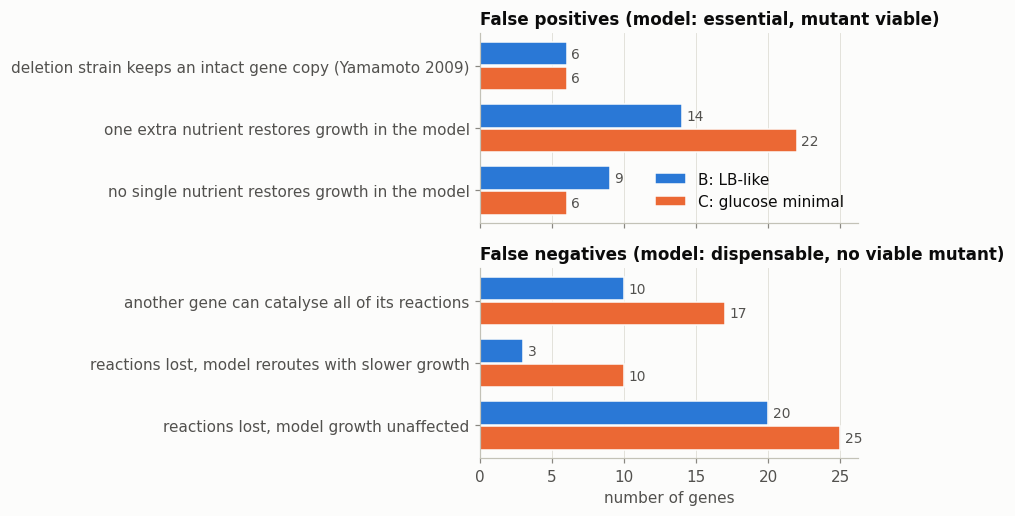

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
panel_titles = {"FP": "False positives (model: essential, mutant viable)", "FN": "False negatives (model: dispensable, no viable mutant)"}
colors = {"B: LB-like": plotting.BLUE, "C: glucose minimal": plotting.ORANGE}

for ax, outcome in zip(axes, ["FP", "FN"]):
    part = group_counts.loc[outcome].iloc[::-1]
    y = np.arange(len(part))
    for offset, name in [(0.2, "B: LB-like"), (-0.2, "C: glucose minimal")]:
        bars = ax.barh(y + offset, part[name], height=0.38, color=colors[name], label=name)
        ax.bar_label(bars, padding=3, fontsize=9, color=plotting.INK_SECONDARY)
    ax.set_yticks(y, part.index)
    ax.set_title(panel_titles[outcome])
    ax.grid(axis="y", visible=False)
axes[1].set_xlabel("number of genes")
axes[0].legend(loc="lower right")
fig.tight_layout()
plotting.save_figure(fig, "error_evidence_groups")
plt.show()

## 5. Diagnostic scenarios

Each scenario changes one assumption, reruns the whole screen and reports what happens to **all** genes, not only to the errors it was meant to explain. A scenario that removes false positives can create new false negatives.

| Scenario | Change | Where the idea comes from |
|---|---|---|
| C1 | add thiamin, biotin, nicotinate and pantothenate to glucose minimal medium | Bernstein et al. (2023) found that iML1515 mispredicts vitamin and cofactor biosynthesis genes in pooled fitness data and suggested the mutants obtain these compounds by cross-feeding or carry-over. Folate, also on their list, has no exchange reaction in iML1515. |
| C2 | add taurine (a sulfonate) to glucose minimal medium | The experimental medium is buffered with MOPS, itself a sulfonate. Orth & Palsson (2012) note MOPS as a possible alternative sulfur source. MOPS is not in the model, so taurine stands in for it. |
| C3 | make the reaction GHMT2r irreversible (serine to glycine only) | Bernstein et al. (2023) trace the wrong predictions for *serA*, *serB*, *serC* to this reaction running backwards. |
| B1 | add biotin and L-glutamine to the LB-like medium | Both are missing from the in-silico LB list although the rescue screen shows several false positives depend on them. Whether real LB supplies enough of each is an assumption to check. |

Naming note: Bernstein et al. (2023) treat "non-essential" (high fitness) as the positive class, so the vitamin-gene errors they call *false negatives* are *false positives* here, and their serine-gene *false positives* are *false negatives* here.

In [13]:
def run_scenario(name, extra_nutrients=(), modify=None):
    spec = COMPARISONS[name]
    medium = dict(spec["medium"]) | {exchange: media.DEFAULT_LB_UPTAKE for exchange in extra_nutrients}
    with model:
        media.apply_medium(model, medium)
        if modify is not None:
            modify(model)
        result = knockout.run_knockouts(model)
    result["predicted_essential"] = knockout.classify_essential(result["growth_ratio"])
    observed = labels.rename(columns={spec["label"]: "observed_essential"})
    return evaluate.compare(result, observed)


def make_ghmt2r_irreversible(m):
    m.reactions.GHMT2r.lower_bound = 0.0


SCENARIOS = {
    "C1: + thiamin, biotin, nicotinate, pantothenate": ("C: glucose minimal", dict(extra_nutrients=["EX_thm_e", "EX_btn_e", "EX_nac_e", "EX_pnto__R_e"])),
    "C2: + taurine (sulfonate)": ("C: glucose minimal", dict(extra_nutrients=["EX_taur_e"])),
    "C3: GHMT2r irreversible": ("C: glucose minimal", dict(modify=make_ghmt2r_irreversible)),
    "B1: + biotin, L-glutamine": ("B: LB-like", dict(extra_nutrients=["EX_btn_e", "EX_gln__L_e"])),
}
gene_name = dict(zip(comparison["C: glucose minimal"]["gene_id"], comparison["C: glucose minimal"]["gene_name"]))

rows = []
for name, table in comparison.items():
    m = evaluate.metrics(evaluate.confusion_counts(table["outcome"]))
    rows.append({"scenario": f"{name} (baseline)"} | {k: m[k] for k in ["TP", "FP", "FN", "precision", "recall", "mcc"]} | {"errors resolved": "", "new errors": ""})

for scenario, (base_name, options) in SCENARIOS.items():
    result = run_scenario(base_name, **options)
    before = comparison[base_name].set_index("gene_id")["outcome"]
    after = result.set_index("gene_id")["outcome"]
    changed = before.index[before != after]
    resolved = sorted(gene_name[g] for g in changed if after[g] in ("TP", "TN"))
    created = sorted(gene_name[g] for g in changed if after[g] in ("FP", "FN"))
    m = evaluate.metrics(evaluate.confusion_counts(result["outcome"]))
    rows.append({"scenario": scenario} | {k: m[k] for k in ["TP", "FP", "FN", "precision", "recall", "mcc"]}
                | {"errors resolved": ", ".join(resolved), "new errors": ", ".join(created)})

scenarios = pd.DataFrame(rows).set_index("scenario")
scenarios.round(4).to_csv(TABLES_DIR / "scenarios.csv")
scenarios.round(3)

,TP,FP,FN,precision,recall,mcc,errors resolved,new errors
scenario,,,,,,,,
B: LB-like (baseline),87,29,33,0.750,0.725,0.715,,
C: glucose minimal (baseline),161,34,52,0.826,0.756,0.757,,
"C1: + thiamin, biotin, nicotinate, pantothenate",148,22,65,0.871,0.695,0.746,"bioA, fabH, nadB, nadC, thiC, thiD, thiE, thiF, thiG, thiH, thiI, thiS","bioB, bioC, bioD, bioF, bioH, fabB, fabI, fabZ, iscS, nadA, panB, panC, panD"
C2: + taurine (sulfonate),160,30,53,0.842,0.751,0.764,"cysC, cysD, cysN, cysQ",cysH
C3: GHMT2r irreversible,164,34,49,0.828,0.770,0.767,"serA, serB, serC",
"B1: + biotin, L-glutamine",84,21,36,0.800,0.700,0.728,"bioA, bioB, bioC, bioD, bioF, bioH, fabH, glnA","fabB, fabI, fabZ"


## 6. Interpretation

Possible causes to choose from: **regulation** (the alternative exists but is not expressed or too slow), **missing pathway** (the cell has a route the model lacks), **annotation error** (wrong gene-reaction rule, wrong reversibility), **medium mismatch** (the simulated medium differs from the real one), **label noise** (the experimental call is doubtful), **outside the model's scope** (the gene's essential role is not metabolic).

The assignments below are hypotheses based on the evidence in this notebook and on the cited literature; none was tested experimentally.

| Evidence group | Example genes | Most likely cause | Why I think so |
|---|---|---|---|
| FP: deletion strain keeps an intact gene copy | *coaA*, *coaE*, *folP*, *glmM*, *hemE*, *lptB* | label noise | Yamamoto et al. (2009) found an intact gene copy in both isolates, so the viable "mutant" does not show that the gene is dispensable; the model is probably right. |
| FP: one extra nutrient restores growth | *thiC*–*thiS*, *cysC*, *cysD*, *cysN*, *cysQ*, *nadB*, *nadC*, *bioA* | medium mismatch, partly borderline growth | Thiamin resolves all eight thiamin genes without new errors, and the minimal-medium cultures were inoculated directly from LB (question 2). But *bioA*, *nadC* and *cysC*, *cysD*, *cysN* grow only weakly near the cut-off, and the non-growing *bioB*–*bioH* and *cysH* mutants argue against a general supply of biotin or of a sulfonate. |
| FP: no single nutrient restores growth | *folB*, *kdsC*, *luxS*, *mtn*, *yrbG*, *zupT* | missing pathway or annotation error | The model has no way around these deletions although the mutants grow (OD600 0.10 to 0.37 after 48 h); a missing isoenzyme or route in the reconstruction is the simplest explanation and would need curation. |
| FN: another gene can catalyse all of its reactions | *metE* (*metH*), *leuB* (*dmlA*), *ilvA* (*tdcB*), *thrA* and *metL* (*lysC*) | regulation, encoded as a too permissive gene rule | The rules list isoenzymes without their conditions: MetH needs vitamin B12, which glucose minimal medium lacks; *dmlA* is induced by D-malate; TdcB belongs to threonine degradation and is expressed under other conditions (Bernstein et al. 2023, question 4). |
| FN: reactions lost, model reroutes with slower growth | *serA*, *serB*, *serC*, *glyA*, *atpB*, *atpC* | annotation error (reversibility) and regulation or enzyme capacity | Making GHMT2r irreversible fixes the three serine genes (scenario C3). The *glyA* knockout relies on threonine-derived glycine, which the mutant evidently cannot use (case study). The *atp* mutants are borderline: OD600 0.044 and 0.054 in the experiment, 32 % growth in the model. |
| FN: reactions lost, model growth unaffected | *spoT*, *nrdA*, *nrdB*, *plsB*, *pgsA*, *lnt* | outside the model's scope, and regulation | *spoT* deletions are lethal in *relA*⁺ strains (Xiao et al. 1991), which is attributed to accumulation of the alarmone (p)ppGpp, a regulatory effect. For *nrdA* and *nrdB* the model switches to ribonucleotide reductases that the cell uses only under other conditions (question 5). For the lipid and lipoprotein genes the model either does not need the lost reactions for biomass or replaces them. |

**Questions and answers**

1. *All eight thiamin genes are false positives in comparison C, and adding thiamin resolves them without creating new errors among the thiamin genes. For biotin it is different: look at which bio genes are resolved and which become new errors in scenario C1. What does that tell you about each vitamin?*
   Biotin resolves only *bioA*, while *bioB*, *bioC*, *bioD*, *bioF* and *bioH* become new false negatives: their mutants do not grow in glucose MOPS medium (OD600 0.035 to 0.065 after 48 h). So the thiamin genes are consistent with thiamin, or a precursor, being available to the mutants in the assay, whereas biotin evidently was not. *bioA* is the exception, and its growth is borderline (OD600 0.109, just above the 0.08 cut-off). Scenario C1 also turns *fabB*, *fabI* and *fabZ* into new errors, as does B1, where biotin is the shared addition: in the model these fatty acid genes are essential only through biotin synthesis.

2. *Read the "Growth tests" paragraph in the Methods of Baba et al. (2006). How were the minimal-medium cultures inoculated? Could nutrients have been carried over?*
   The mutants were first grown for 22 h at 37 °C without shaking in 200 µl LB with kanamycin in 96-well plates, then transferred with 96-pin replicators from LB into 200 µl 0.4 % glucose MOPS medium with 2 mM phosphate and kanamycin, and read after 24 and 48 h. No washing step is described, so cells and a small volume of LB were carried into the minimal medium, and nutrients from LB, or stored inside the cells, could have been carried over. Each mutant grew in its own well, so cross-feeding between different mutants, as in pooled fitness experiments, is unlikely in this assay. Whether the carried-over amounts suffice for the observed growth was not tested here.

3. *Scenario C1 removes false positives but does not improve the MCC. Why would it be wrong to adopt it as "the corrected model"?*
   C1 lowers the false positives from 34 to 22 but raises the false negatives from 52 to 65, so precision rises (0.826 to 0.871), recall falls (0.756 to 0.695) and MCC drops slightly (0.757 to 0.746). Adopting it would mean choosing a medium assumption after looking at the errors, which inflates the apparent fit. The assumption is also contradicted by the data: the non-growing biotin, pantothenate and *nadA* mutants show that those vitamins were not available. And it changes the simulated experiment rather than correcting the model.

4. *Pick three false negatives that have `backup_genes`. Look the backup genes up in EcoCyc: under which conditions are they expressed? Does that explain why the cell cannot rely on them?*
   Bernstein et al. (2023) discuss the same three pairs and cite the primary literature (EcoCyc itself was not consulted for this answer):
   - *metE* (backup *metH*): MetH is the vitamin B12 (cobalamin)-dependent methionine synthase (González et al. 1992), and glucose minimal medium contains no B12. In the Keio data the *metE* mutant does not grow (OD600 0.009), the *metH* mutant does (0.509).
   - *leuB* (backup *dmlA*): *dmlA* expression is induced more than 50-fold by D-malate compared with L-malate, glucose or glycerol (Stern & Hegre 1966), so DmlA is not available in glucose medium.
   - *ilvA* (backup *tdcB*): TdcB is a catabolic threonine dehydratase involved in threonine degradation and is not expressed under the same conditions as IlvA (Egan & Phillips 1977).

   In all three cases the gene rule lists an isoenzyme that the cell does not have, or cannot use, in glucose minimal medium, which explains why the model is too optimistic.

5. *Some false negatives are essential in every experimental source (`pec` = E) and their reactions are lost in the model without any effect on growth. What would have to be true of the model for that to happen?*
   In comparison C these are *adk*, *fabA*, *fbaA*, *lnt*, *nrdA*, *nrdB*, *pgsA*, *plsB*, *prs* and *spoT*. For growth to be unaffected, the model must either produce the products of the lost reactions in another way or not need them for biomass at all. *nrdA* and *nrdB* show the first case: besides the aerobic class Ia reductase NrdAB, the model contains the class Ib reductase NrdEF and the anaerobic class III reductase NrdDG, whose gene rules remain satisfied. In the cell, NrdEF supports replication mainly during iron starvation (Martin & Imlay 2011), and the glycyl-radical enzyme NrdD works only under anaerobic conditions. *spoT* shows the second case: its essential function, preventing toxic accumulation of (p)ppGpp, is not part of the biomass objective.

6. *Which errors would you not blame on the model at all?*
   - The six false positives whose deletion strains keep an intact gene copy (label noise).
   - Borderline growth near the 0.08 cut-off: *bioA* (0.109), *nadC* (0.114) and *cysC*, *cysD*, *cysN* (0.12 to 0.16; *cysC* is below the cut-off at 24 h), and on the false-negative side *atpB* and *atpC* (0.044 and 0.054), which the model predicts to grow at only 32 % of wild type.
   - Probably the thiamin genes, if their growth comes from carry-over from the LB pre-culture, which is a property of the assay, not of the model.

References used in these answers:
- Baba T. et al. (2006) *Mol Syst Biol* 2:2006.0008. https://doi.org/10.1038/msb4100050
- Bernstein D.B. et al. (2023) *Mol Syst Biol* 19:e11566. https://doi.org/10.15252/msb.202311566
- Egan & Phillips (1977) and González et al. (1992), cited by Bernstein et al. (2023)
- Martin J.E., Imlay J.A. (2011) *Mol Microbiol* 80:319–334. https://doi.org/10.1111/j.1365-2958.2011.07593.x
- Stern & Hegre (1966), cited by Bernstein et al. (2023)
- Xiao H. et al. (1991) *J Biol Chem* 266:5980–5990. https://doi.org/10.1016/S0021-9258(19)67694-5

## Notes

**Observations**
- Thiamin and biotin genes respond in opposite ways to the same supplement, so "vitamin availability" is not one explanation but a separate question for each vitamin.
- Every scenario resolves some errors and creates others; the largest change in MCC is +0.013 (B1).
- The *glyA* knockout survives in the model only through threonine-derived glycine, and the serine genes only through GHMT2r running backwards. Both point to the glycine–serine node as a weak spot of the model.

**To check next**
- Literature on growth of *glyA* mutants with added glycine, to test the case-study hypothesis.
- Whether *E. coli* can use MOPS as a sulfur source, given that the *cysH* mutant does not grow.
- Curation of the six false positives that no single nutrient rescues (*folB*, *kdsC*, *luxS*, *mtn*, *yrbG*, *zupT*) against EcoCyc and the literature.